# Work in progress

This file is a work in progress and is subject to change before the final deadline

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

print("Imports successful")
csv = pd.read_csv('chessData_formatted.csv', nrows=1_000_000)
print("Read CSV successful")

Imports successful
Read CSV successful


In [2]:
SEED = 67
def displayGraph(data, y_kmeans, labels):
    plt.figure(figsize=[9,5])
    scatter = plt.scatter(data[:, 0], data[:, 1], s=10, c=y_kmeans, cmap="viridis")
    handles, _ = scatter.legend_elements()
    plt.legend(handles=handles, labels=labels, title="Cluster", loc="upper right", frameon=True, framealpha=1, facecolor="white", edgecolor="black")
    plt.xlabel('Full Moves')
    plt.ylabel('Evaluation')
    plt.xlim(0)
    plt.show()

Silhouette Score:  0.5110590957427922


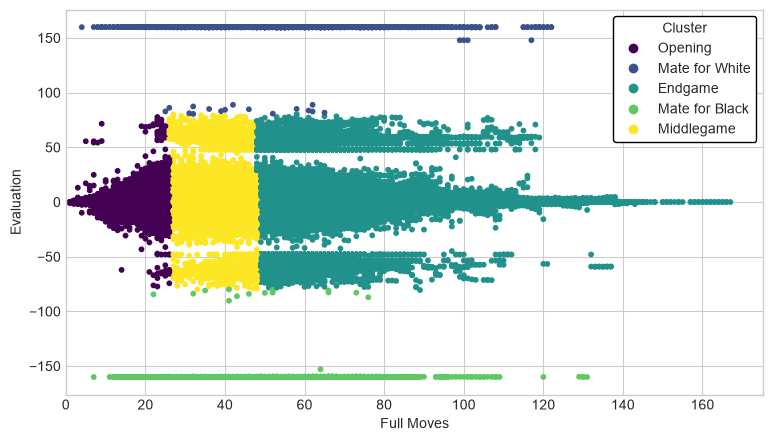

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

fullMoves = csv["fullMoves"].values
evaluation = csv["Evaluation"].values / 100

kmeans = KMeans(n_clusters=5, random_state=SEED)
data = np.column_stack((fullMoves, evaluation))
kmeans.fit(data)
y_kmeans = kmeans.predict(data)

score = silhouette_score(data, y_kmeans, sample_size=10_000, random_state=SEED)
print("Silhouette Score: ", score)

displayGraph(data, y_kmeans, ["Opening", "Mate for White", "Endgame", "Mate for Black", "Middlegame"])

Silhouette score:  0.5067012316730681


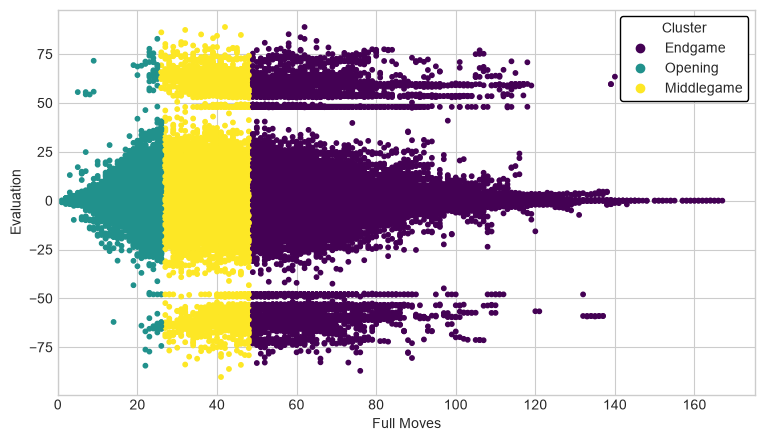

In [4]:
mask = np.abs(data[:, 1]) < 100
cappedData = data[mask]

capped_kmeans = KMeans(n_clusters=3, random_state=SEED)
capped_kmeans.fit(cappedData)
capped_y_kmeans = capped_kmeans.predict(cappedData)

score2 = silhouette_score(cappedData, capped_y_kmeans, sample_size=10_000, random_state=SEED)
print("Silhouette score: ", score2)

displayGraph(cappedData, capped_y_kmeans, ["Endgame", "Opening", "Middlegame"])

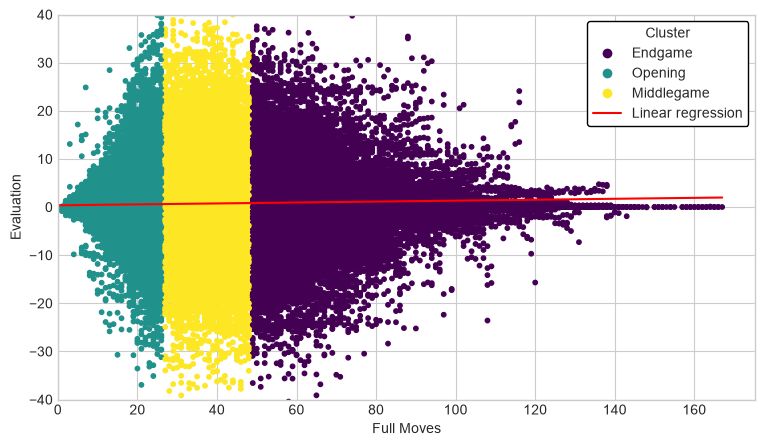

In [5]:
from sklearn.linear_model import LinearRegression

model = LinearRegression(fit_intercept=True)

x = data[:, 0]
y = data[:, 1]
model.fit(x[:, np.newaxis], y)
xfit = np.linspace(0, x.max())
yfit = model.predict(xfit[:, np.newaxis])

plt.figure(figsize=[9, 5])
scatter = plt.scatter(cappedData[:, 0], cappedData[:, 1], s=10, c=capped_y_kmeans, cmap="viridis")
cluster_handles, _ = scatter.legend_elements()

line, = plt.plot(xfit, yfit, color="red", label="Linear regression")

plt.legend(handles=cluster_handles + [line],
           labels=["Endgame", "Opening", "Middlegame", "Linear regression"],
           title="Cluster",
           loc="upper right",
           frameon=True,
           framealpha=1,
           facecolor="white",
           edgecolor="black"
           )

plt.xlabel('Full Moves')
plt.ylabel('Evaluation')
plt.xlim(0)
plt.ylim(-40, 40)
plt.show()